
RESULTADO DEL MODELO DE REGRESIÓN LINEAL
R² Obtenido: 0.3422  (Requisito: R² > 0.30)
R² Ajustado: 0.3388
RMSE: $821,681.35
MAE:  $524,916.79


,coef,std err,t,P>|t|,[0.025,0.975]
const,-1.317e+06,1.78e+05,-7.410,0.000,-1.67e+06,-9.68e+05
HORAS_SEM,9646.0654,1110.535,8.686,0.000,7468.224,1.18e+04
EDAD,4.559e+04,7647.415,5.962,0.000,3.06e+04,6.06e+04
EDAD_2,-442.4307,85.272,-5.188,0.000,-609.655,-275.207
ES_VARON,3.387e+05,3.75e+04,9.035,0.000,2.65e+05,4.12e+05
ES_CABA,2.509e+05,4.34e+04,5.779,0.000,1.66e+05,3.36e+05
NIVEL_ED_NUM,1.264e+05,1.61e+04,7.867,0.000,9.49e+04,1.58e+05
ES_PROFESIONAL,6.651e+05,6.86e+04,9.689,0.000,5.3e+05,8e+05
ES_TECNICO,9.876e+04,5.35e+04,1.846,0.065,-6183.911,2.04e+05
ES_FORMAL,3.495e+05,3.81e+04,9.171,0.000,2.75e+05,4.24e+05



--- RESUMEN DE INGRESOS IMPUTADOS PARA LA NO RESPUESTA ---


,Casos,Media_Imputada,Mediana_Imputada,Min,Max
AGLOMERADO,,,,,
CABA,205,1817522.98,1707761.75,8690.27,3725567.38
GBA,847,1034932.59,993064.44,6000.00,2977564.29


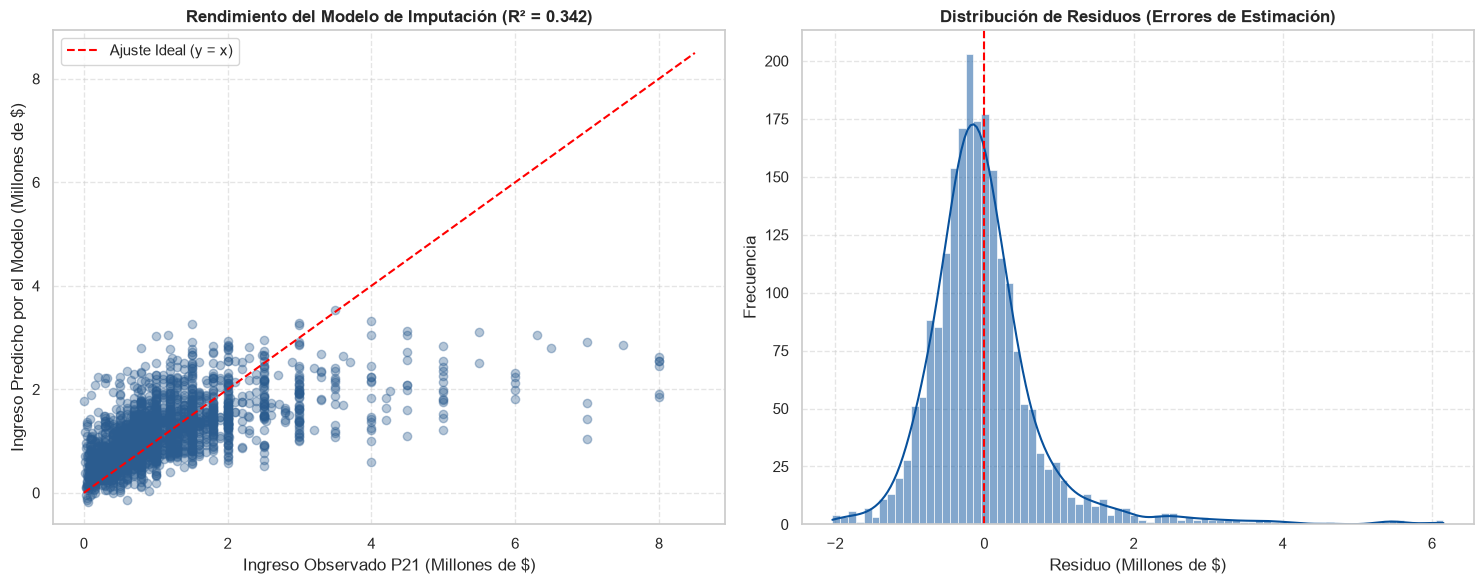

In [ ]:
# MODELO DE REGRESIÓN PARA LA IMPUTACIÓN DE NO RESPUESTA (P21)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Configuración visual
sns.set_theme(style="whitegrid")
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 1. Cargar el trimestre completo de T2 2026
ruta_t226 = "../datos/raw/usu_individual_T226.txt"
df_modelo_raw = pd.read_csv(ruta_t226, sep=";", low_memory=False)
df_modelo_raw.columns = [c.upper().strip() for c in df_modelo_raw.columns]

# Filtrar CABA (32) y GBA (33) en población ocupada (ESTADO == 1)
df_modelo = df_modelo_raw[df_modelo_raw['AGLOMERADO'].isin([32, 33])].copy()
df_ocupados = df_modelo[df_modelo['ESTADO'] == 1].copy()

# 2. Ingeniería de variables explicativas
# Horas trabajadas
df_ocupados['HORAS_SEM'] = pd.to_numeric(df_ocupados['PP3E_TOT'], errors='coerce')
df_ocupados.loc[df_ocupados['HORAS_SEM'] > 120, 'HORAS_SEM'] = np.nan
df_ocupados['HORAS_SEM'] = df_ocupados['HORAS_SEM'].fillna(df_ocupados['HORAS_SEM'].median())

# Edad y Edad al cuadrado
df_ocupados['EDAD'] = pd.to_numeric(df_ocupados['CH06'], errors='coerce')
df_ocupados = df_ocupados[df_ocupados['EDAD'] >= 14].copy()
df_ocupados['EDAD_2'] = df_ocupados['EDAD'] ** 2

# Demografía y geografía
df_ocupados['ES_VARON'] = (pd.to_numeric(df_ocupados['CH04'], errors='coerce') == 1).astype(int)
df_ocupados['ES_CABA'] = (pd.to_numeric(df_ocupados['AGLOMERADO'], errors='coerce') == 32).astype(int)

# Nivel Educativo
df_ocupados['NIVEL_ED_NUM'] = pd.to_numeric(df_ocupados['NIVEL_ED'], errors='coerce').replace({7: 1})
df_ocupados['NIVEL_ED_NUM'] = df_ocupados['NIVEL_ED_NUM'].fillna(df_ocupados['NIVEL_ED_NUM'].median())

# Calificación ocupacional (PP04D_COD)
def extraer_profesional(cod):
    try: return 1 if str(int(float(cod))).zfill(5)[-1] == '1' else 0
    except: return 0

def extraer_tecnico(cod):
    try: return 1 if str(int(float(cod))).zfill(5)[-1] == '2' else 0
    except: return 0

df_ocupados['ES_PROFESIONAL'] = df_ocupados['PP04D_COD'].apply(extraer_profesional)
df_ocupados['ES_TECNICO'] = df_ocupados['PP04D_COD'].apply(extraer_tecnico)

# Formalidad y Patrón
df_ocupados['ES_FORMAL'] = (pd.to_numeric(df_ocupados['PP07H'], errors='coerce') == 1).astype(int)
df_ocupados['ES_PATRON'] = (pd.to_numeric(df_ocupados['CAT_OCUP'], errors='coerce') == 1).astype(int)

# Sector Alto Ingreso (CAES 58 a 75)
def es_sector_alto(cod):
    try:
        c = int(float(str(int(float(cod)))[:2]))
        return 1 if (58 <= c <= 75) else 0
    except: return 0

df_ocupados['SECTOR_ALTO_INGRESO'] = df_ocupados['PP04B_COD'].apply(es_sector_alto)

# 3. Conjuntos de Entrenamiento y No Respuesta
df_ocupados['P21'] = pd.to_numeric(df_ocupados['P21'], errors='coerce')
df_train_opt = df_ocupados[(df_ocupados['P21'] > 0) & (df_ocupados['P21'] <= 8500000)].copy()
df_imputar_opt = df_ocupados[df_ocupados['P21'] == -9].copy()

features_opt = [
    'HORAS_SEM', 'EDAD', 'EDAD_2', 'ES_VARON', 'ES_CABA', 
    'NIVEL_ED_NUM', 'ES_PROFESIONAL', 'ES_TECNICO', 
    'ES_FORMAL', 'ES_PATRON', 'SECTOR_ALTO_INGRESO'
]

X_opt = df_train_opt[features_opt]
y_opt = df_train_opt['P21']

# 4. Ajuste OLS
X_opt_const = sm.add_constant(X_opt)
modelo_opt = sm.OLS(y_opt, X_opt_const).fit()

# Métricas
y_pred_opt = modelo_opt.predict(X_opt_const)
r2_opt = r2_score(y_opt, y_pred_opt)
rmse_opt = np.sqrt(mean_squared_error(y_opt, y_pred_opt))
mae_opt = mean_absolute_error(y_opt, y_pred_opt)

print("\n" + "="*55)
print("RESULTADO DEL MODELO DE REGRESIÓN LINEAL")
print(f"R² Obtenido: {r2_opt:.4f}  (Requisito: R² > 0.30)")
print(f"R² Ajustado: {modelo_opt.rsquared_adj:.4f}")
print(f"RMSE: ${rmse_opt:,.2f}")
print(f"MAE:  ${mae_opt:,.2f}")
print("="*55)

display(modelo_opt.summary().tables[1])

# 5. Imputación sobre la No Respuesta (-9)
X_no_resp = sm.add_constant(df_imputar_opt[features_opt], has_constant='add')
df_imputar_opt['P21_IMPUTADO'] = modelo_opt.predict(X_no_resp).clip(lower=df_train_opt['P21'].min())

print("\n--- RESUMEN DE INGRESOS IMPUTADOS PARA LA NO RESPUESTA ---")
display(df_imputar_opt.groupby('AGLOMERADO')['P21_IMPUTADO'].agg(
    Casos='count',
    Media_Imputada='mean',
    Mediana_Imputada='median',
    Min='min',
    Max='max'
).rename(index={32: 'CABA', 33: 'GBA'}).round(2))

# 6. Gráficos de Evaluación del Modelo
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(y_opt / 1e6, y_pred_opt / 1e6, alpha=0.35, color='#2b5c8f')
axes[0].plot([0, 8.5], [0, 8.5], color='red', linestyle='--', label='Ajuste Ideal (y = x)')
axes[0].set_title(f'Rendimiento del Modelo de Imputación (R² = {r2_opt:.3f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Ingreso Observado P21 (Millones de $)')
axes[0].set_ylabel('Ingreso Predicho por el Modelo (Millones de $)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

residuos_opt = y_opt - y_pred_opt
sns.histplot(residuos_opt / 1e6, kde=True, color='#08519c', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Distribución de Residuos (Errores de Estimación)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residuo (Millones de $)')
axes[1].set_ylabel('Frecuencia')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
fig.savefig("graficos_modelo_imputacion_r2.png", dpi=300, bbox_inches='tight')
plt.show()